# Quantum Algorithms: Deutsch-Jozsa, Grover, QFT, Shor, VQE and QAOA

> **Who is this for:** learners who finished [01_quantum_computing_basics.ipynb](01_quantum_computing_basics.ipynb) and want to see what quantum computers are actually *for*.
>
> **What you will learn:**
> - the common shape of quantum algorithms: **superposition, oracle, interference, measurement**
> - **Deutsch-Jozsa** and **Bernstein-Vazirani**: the first "one query instead of many" examples
> - **Grover search** on 3 qubits with a plot of **amplitude amplification**
> - the **quantum Fourier transform (QFT)** and **phase estimation**, in a simple form
> - **Shor's algorithm**: the idea, a small simulation of its period-finding step, and why it threatens RSA (which leads to **post-quantum cryptography**)
> - **variational algorithms**: **VQE** (find the lowest energy of a tiny Hamiltonian) and **QAOA** (MaxCut on a 4-node graph), both with a classical optimiser
> - a table of **speedup types**: exponential, quadratic, and none known
>
> **Prerequisites:** [01_quantum_computing_basics.ipynb](01_quantum_computing_basics.ipynb) (we reuse its simulator), [linear algebra](../14_Mathematics/01_linear_algebra.ipynb) (eigenvalues help for VQE), [optimization](../14_Mathematics/06_optimization.ipynb) (helpful for VQE/QAOA).
>
> **Time needed:** about 2-3 hours. The notebook runs in well under a minute.
>
> **Runs on:** CPU, no API key, no internet. numpy, scipy and matplotlib only.

## 0. Setup

Imports, a fixed seed, and the same small statevector simulator we built in notebook 01 (pasted into one cell so this notebook runs on its own). Remember: in a bitstring like `101`, **qubit 0 is the left-most bit**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from fractions import Fraction
from math import gcd
from scipy.optimize import minimize

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)

In [2]:
# ---- The tiny statevector simulator from notebook 01 (same code, in one cell) ----
from collections import Counter

# Single-qubit gates (2x2 matrices)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
S = np.array([[1, 0], [0, 1j]], dtype=complex)
T = np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

def RX(t): return np.array([[np.cos(t/2), -1j*np.sin(t/2)], [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RY(t): return np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RZ(t): return np.array([[np.exp(-1j*t/2), 0], [0, np.exp(1j*t/2)]], dtype=complex)

# Two-qubit gates (4x4). The first qubit listed is the control.
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)
CZ = np.diag([1, 1, 1, -1]).astype(complex)

def apply_gate(psi, U, qubits, n):
    """Apply matrix U to the listed qubits of an n-qubit state psi.
    Qubit 0 is the LEFT-most bit of a bitstring like '011'."""
    k = len(qubits)
    psi = psi.reshape([2] * n)
    U = U.reshape([2] * (2 * k))
    psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(qubits)))
    psi = np.moveaxis(psi, list(range(k)), list(qubits))
    return psi.reshape(-1)

class QSim:
    """A tiny statevector simulator. Methods return self, so calls can be chained."""
    def __init__(self, n):
        self.n = n
        self.psi = np.zeros(2 ** n, dtype=complex)
        self.psi[0] = 1.0                      # start in |00...0>
    def gate(self, U, *qubits):
        self.psi = apply_gate(self.psi, U, qubits, self.n); return self
    def x(self, q):  return self.gate(X, q)
    def y(self, q):  return self.gate(Y, q)
    def z(self, q):  return self.gate(Z, q)
    def h(self, q):  return self.gate(H, q)
    def s(self, q):  return self.gate(S, q)
    def t(self, q):  return self.gate(T, q)
    def rx(self, th, q): return self.gate(RX(th), q)
    def ry(self, th, q): return self.gate(RY(th), q)
    def rz(self, th, q): return self.gate(RZ(th), q)
    def cx(self, c, t): return self.gate(CNOT, c, t)
    def cz(self, a, b): return self.gate(CZ, a, b)
    def probs(self):
        return np.abs(self.psi) ** 2
    def measure(self, shots=1000, seed=0):
        """Sample bitstrings like a real device would. Returns a Counter."""
        rng = np.random.default_rng(seed)
        p = self.probs(); p = p / p.sum()
        idx = rng.choice(len(p), size=shots, p=p)
        return Counter(format(i, f"0{self.n}b") for i in idx)

def bitstrings(n):
    return [format(i, f"0{n}b") for i in range(2 ** n)]

def plot_counts(counts, title="", ax=None):
    """Bar chart of measurement counts, with every bitstring on the x-axis."""
    n = len(next(iter(counts)))
    labels = bitstrings(n)
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(labels, [counts.get(b, 0) for b in labels], color="tab:blue")
    ax.set_title(title); ax.set_ylabel("counts")
    ax.tick_params(axis="x", rotation=90 if n > 3 else 0)
    plt.tight_layout()
    return ax

def show_state(psi, tol=1e-9):
    """Print the non-zero amplitudes of a state in ket notation."""
    n = int(np.log2(len(psi)))
    for i, a in enumerate(psi):
        if abs(a) > tol:
            print(f"  |{format(i, f'0{n}b')}>  amplitude {a.real:+.3f}{a.imag:+.3f}j   probability {abs(a)**2:.3f}")

print("Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state")

Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state


In [3]:
# Extra helpers for this notebook
def h_all(sim, qubits=None):
    """Hadamard on every qubit (or on the listed qubits)."""
    for q in (range(sim.n) if qubits is None else qubits):
        sim.h(q)
    return sim

def phase_oracle(f, n):
    """Diagonal matrix with (-1)^f(x) on the diagonal: it 'marks' inputs where f(x) = 1
    by flipping the sign of their amplitude."""
    return np.diag([(-1) ** f(b) for b in bitstrings(n)]).astype(complex)

print("helpers ready")

helpers ready


## 1. The shape of a quantum algorithm

**What it is.** Almost every quantum algorithm follows the same four steps.

```mermaid
flowchart LR
    A[Step 1: superposition<br/>H on every qubit] --> B[Step 2: oracle<br/>mark answers with a phase]
    B --> C[Step 3: interference<br/>H, diffuser or QFT]
    C --> D[Step 4: measure<br/>repeat for many shots]
```

- An **oracle** is a black-box function $f(x)$ that we are allowed to call. In a quantum circuit it is a gate. The **phase oracle** form multiplies the amplitude of $\lvert x\rangle$ by $(-1)^{f(x)}$, so "good" inputs get a minus sign.
- This trick of turning a function value into a phase is called **phase kickback**. (In real circuits it is built from a normal "compute $f(x)$ into a helper qubit" gate, with the helper qubit prepared in $\lvert-\rangle$.)
- We count **queries**: how many times the algorithm calls the oracle. Quantum speedups are usually stated as "fewer queries".

**Simple analogy.** A phase oracle is like a teacher who silently puts an invisible-ink tick next to the right answers. You cannot see invisible ink directly (a phase is not visible to measurement), but the interference step is the UV lamp that makes the ticks visible.

## 2. Deutsch-Jozsa: constant or balanced in one query

**What it is.** We are promised that a function $f$ from n bits to 1 bit is either **constant** (same output for every input) or **balanced** (outputs 0 for exactly half the inputs and 1 for the other half). Which one is it?

- **Classical, with certainty:** in the worst case you must check $2^{n-1}+1$ inputs.
- **Quantum (Deutsch-Jozsa, 1992):** **one** query. Apply H to all qubits, the phase oracle, H to all qubits again, and measure. If $f$ is constant, you get `000...0` with probability 1. If $f$ is balanced, you **never** get `000...0`.

**How it works.** After the last H layer, the amplitude of `00...0` is the *average* of $(-1)^{f(x)}$ over all x. For a constant function that average is ±1. For a balanced function the +1s and -1s cancel exactly (destructive interference) and it is 0.

**Honest caveat.** A *randomised* classical algorithm that checks just a few random inputs is right with very high probability. So Deutsch-Jozsa is a teaching example, not a useful speedup.

In [4]:
n = 3
functions = {
    "constant 0":        lambda b: 0,
    "constant 1":        lambda b: 1,
    "balanced: x0":      lambda b: int(b[0]),                    # first bit
    "balanced: parity":  lambda b: b.count("1") % 2,             # XOR of all bits
    "balanced: random":  (lambda table: (lambda b: table[b]))(   # a random balanced lookup table
        dict(zip(bitstrings(3), rng.permutation([0, 0, 0, 0, 1, 1, 1, 1])))),
}

for name, f in functions.items():
    sim = h_all(QSim(n))                 # 1. superposition
    sim.gate(phase_oracle(f, n), 0, 1, 2) # 2. ONE oracle query
    h_all(sim)                           # 3. interference
    p000 = sim.probs()[0]                # 4. probability of all zeros
    verdict = "CONSTANT" if p000 > 0.5 else "BALANCED"
    print(f"{name:18}  P(000) = {p000:.2f}  ->  {verdict}")

constant 0          P(000) = 1.00  ->  CONSTANT
constant 1          P(000) = 1.00  ->  CONSTANT
balanced: x0        P(000) = 0.00  ->  BALANCED
balanced: parity    P(000) = 0.00  ->  BALANCED
balanced: random    P(000) = 0.00  ->  BALANCED


## 3. Bernstein-Vazirani: read a hidden string in one query (short)

**What it is.** A hidden bitstring $s$ defines $f(x) = s\cdot x \bmod 2$ (multiply bit by bit, add, keep the last bit). Classically each query reveals one bit of $s$, so you need n queries. The same H-oracle-H circuit as Deutsch-Jozsa returns $s$ itself in **one** query.

**Why it works (one line).** The phase oracle turns the uniform superposition into $\tfrac{1}{\sqrt{2^n}}\sum_x (-1)^{s\cdot x}\lvert x\rangle$, which is exactly $H^{\otimes n}\lvert s\rangle$. Applying H again gives $\lvert s\rangle$.

In [5]:
secret = "1011"
n = len(secret)
f = lambda b: sum(int(si) * int(bi) for si, bi in zip(secret, b)) % 2

sim = h_all(QSim(n))
sim.gate(phase_oracle(f, n), *range(n))
h_all(sim)
counts = sim.measure(shots=100, seed=SEED)
print("secret:", secret, "  measured:", counts)

secret: 1011   measured: Counter({'1011': 100})


## 4. Grover search: amplitude amplification

**What it is.** Grover's algorithm (1996) finds a marked item among $N = 2^n$ items using about $\tfrac{\pi}{4}\sqrt{N}$ oracle queries. A classical search needs about $N/2$ queries on average. That is a **quadratic speedup**.

**Simple analogy.** Imagine $N$ people in a stadium, all whispering at the same volume. One person is the "winner". Each Grover round does two things: (1) the oracle makes the winner whisper *upside down* (a minus sign), and (2) the **diffuser** makes everyone "flip around the average volume". People at normal volume barely change, but the upside-down winner jumps far above the average. Repeat, and the winner gets louder each round.

**How it works.**
1. Start in the uniform superposition (H on every qubit). Every amplitude is $1/\sqrt{N}$.
2. **Oracle:** flip the sign of the marked item's amplitude.
3. **Diffuser** $D = 2\lvert s\rangle\langle s\rvert - I$: reflect every amplitude about the average ("inversion about the mean"). $\lvert s\rangle$ is the uniform superposition.
4. Repeat steps 2-3 about $\tfrac{\pi}{4}\sqrt{N}$ times, then measure.

With 3 qubits, $N=8$ and the best number of rounds is 2.

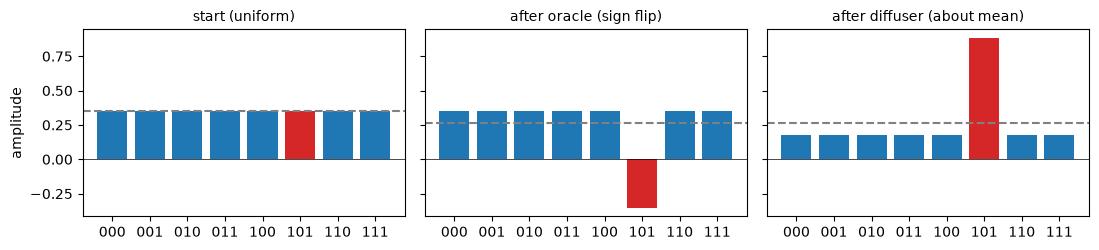

In [6]:
n, target = 3, "101"
N = 2 ** n
oracle = phase_oracle(lambda b: int(b == target), n)          # minus sign on |101>
s_vec = np.ones(N) / np.sqrt(N)                               # uniform superposition |s>
diffuser = 2 * np.outer(s_vec, s_vec) - np.eye(N)             # reflect about the mean

# Look inside ONE round: start -> after oracle -> after diffuser
sim = h_all(QSim(n))
snapshots = {"start (uniform)": sim.psi.real.copy()}
sim.gate(oracle, 0, 1, 2);   snapshots["after oracle (sign flip)"] = sim.psi.real.copy()
sim.gate(diffuser, 0, 1, 2); snapshots["after diffuser (about mean)"] = sim.psi.real.copy()

fig, axes = plt.subplots(1, 3, figsize=(11, 2.6), sharey=True)
for ax, (name, amps) in zip(axes, snapshots.items()):
    colors = ["tab:red" if b == target else "tab:blue" for b in bitstrings(n)]
    ax.bar(bitstrings(n), amps, color=colors); ax.axhline(amps.mean(), ls="--", c="gray")
    ax.set_title(name, fontsize=10); ax.axhline(0, c="k", lw=0.5)
axes[0].set_ylabel("amplitude"); plt.tight_layout(); plt.show()

**What just happened?** The dashed line is the average amplitude. After the oracle, the target (red) is negative, which pulls the average down a little. Reflecting everything about that average makes the target's amplitude jump from about 0.35 to about 0.88. Now let us repeat the round several times and track the success probability.

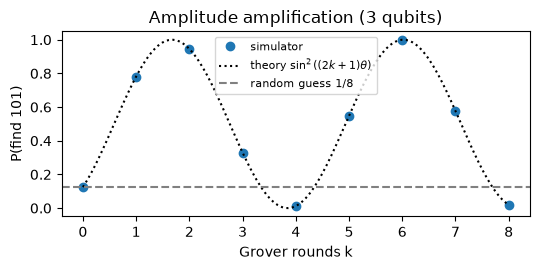

rounds=0: P(target)=0.125
rounds=1: P(target)=0.781
rounds=2: P(target)=0.945
rounds=3: P(target)=0.330
rounds=4: P(target)=0.012
rounds=5: P(target)=0.548
rounds=6: P(target)=1.000
rounds=7: P(target)=0.577
rounds=8: P(target)=0.019


In [7]:
def grover_success(n_rounds):
    sim = h_all(QSim(n))
    for _ in range(n_rounds):
        sim.gate(oracle, 0, 1, 2).gate(diffuser, 0, 1, 2)
    return sim.probs()[int(target, 2)]

rounds = range(0, 9)
p_success = [grover_success(k) for k in rounds]
theta = np.arcsin(1 / np.sqrt(N))                                # theory: P = sin^2((2k+1) theta)
k_fine = np.linspace(0, 8, 200)

plt.figure(figsize=(5.5, 2.8))
plt.plot(rounds, p_success, "o", label="simulator")
plt.plot(k_fine, np.sin((2 * k_fine + 1) * theta) ** 2, "k:", label=r"theory $\sin^2((2k+1)\theta)$")
plt.axhline(1 / N, c="gray", ls="--", label="random guess 1/8")
plt.xlabel("Grover rounds k"); plt.ylabel("P(find 101)"); plt.legend(fontsize=8)
plt.title("Amplitude amplification (3 qubits)"); plt.tight_layout(); plt.show()
for k, p in zip(rounds, p_success):
    print(f"rounds={k}: P(target)={p:.3f}")

2 rounds, 1000 shots, most common result: [('101', 944)]


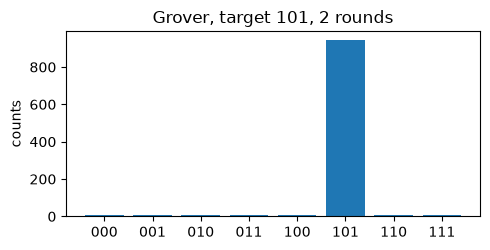


Queries needed (illustrative): classical average N/2 vs Grover ~ (pi/4) sqrt(N)
  N = 2^3   classical ~                4   Grover ~            2
  N = 2^10  classical ~              512   Grover ~           25
  N = 2^20  classical ~          524,288   Grover ~          804
  N = 2^40  classical ~  549,755,813,888   Grover ~      823,550


In [8]:
# Run the best number of rounds (2) with shots, like on a device
best = int(np.floor(np.pi / 4 * np.sqrt(N)))
sim = h_all(QSim(n))
for _ in range(best):
    sim.gate(oracle, 0, 1, 2).gate(diffuser, 0, 1, 2)
counts = sim.measure(shots=1000, seed=SEED)
print(f"{best} rounds, 1000 shots, most common result: {counts.most_common(1)}")
plot_counts(counts, f"Grover, target {target}, {best} rounds"); plt.show()

print("\nQueries needed (illustrative): classical average N/2 vs Grover ~ (pi/4) sqrt(N)")
for n_bits in [3, 10, 20, 40]:
    NN = 2 ** n_bits
    print(f"  N = 2^{n_bits:<3} classical ~ {NN/2:>16,.0f}   Grover ~ {np.pi/4*np.sqrt(NN):>12,.0f}")

**What just happened?**
- The success probability goes up, peaks at 2 rounds (about 0.95), and then goes **down** again (it comes back up later, because Grover is a rotation). Too many rounds overshoot the target. You must know (or estimate) how many items are marked.
- With 1000 shots, `101` dominates the histogram.

**When to use it and when not.**
- The speedup is only **quadratic**. Every Grover round is a long, deep circuit, and real hardware gates are millions of times slower than a CPU instruction. Published resource estimates suggest that, with error-corrected hardware, quadratic speedups need very large problems before they beat a classical computer at all.
- Grover needs the oracle as a quantum circuit. For "search a database", loading the database into the quantum computer already costs about $N$ steps, which wipes out the gain.
- The general idea, **amplitude amplification**, is still important: it speeds up many other quantum algorithms, and **amplitude estimation** gives a quadratic speedup for Monte Carlo estimation (used in finance proposals, notebook 04).

## 5. The quantum Fourier transform and phase estimation (simple)

### 5.1 QFT

**What it is.** The **quantum Fourier transform** is the discrete Fourier transform (the maths behind the FFT) applied to the $2^n$ amplitudes of a state:

$$\text{QFT}\lvert x\rangle = \frac{1}{\sqrt{N}}\sum_{y=0}^{N-1} e^{2\pi i\, x y / N}\lvert y\rangle$$

**Simple analogy.** A music app that turns a sound wave into a list of notes (frequencies). The QFT turns a state with a repeating pattern (a **period**) into a state whose big amplitudes sit at the matching frequencies.

**How it works.** It needs only about $n^2/2$ gates (Hadamards and **controlled-phase** gates, plus swaps), while the classical FFT of $2^n$ numbers needs about $n\,2^n$ steps. The catch: you cannot read the $2^n$ output amplitudes, only sample from them. So the QFT is useful only inside algorithms that need a *sample* of the frequency, such as phase estimation and Shor.

In [9]:
def qft_matrix(n):
    N = 2 ** n
    j, k = np.meshgrid(np.arange(N), np.arange(N), indexing="ij")
    return np.exp(2j * np.pi * j * k / N) / np.sqrt(N)

def CP(phi):                                        # controlled-phase gate
    return np.diag([1, 1, 1, np.exp(1j * phi)]).astype(complex)
SWAP = np.array([[1,0,0,0],[0,0,1,0],[0,1,0,0],[0,0,0,1]], dtype=complex)

def qft_circuit(sim, qubits):
    """QFT built from H, controlled-phase and SWAP gates (qubits[0] = most significant bit)."""
    m = len(qubits)
    for a in range(m):
        sim.h(qubits[a])
        for b in range(a + 1, m):
            sim.gate(CP(np.pi / 2 ** (b - a)), qubits[b], qubits[a])
    for a in range(m // 2):
        sim.gate(SWAP, qubits[a], qubits[m - 1 - a])
    return sim

n = 3
F = qft_matrix(n)
print("QFT matrix is unitary:", np.allclose(F.conj().T @ F, np.eye(2 ** n)))
print("QFT = inverse FFT x sqrt(N):", np.allclose(F @ np.eye(8)[:, 5], np.fft.ifft(np.eye(8)[:, 5]) * np.sqrt(8)))

# Build the circuit version column by column and compare with the matrix
U_circ = np.zeros((8, 8), dtype=complex)
for x in range(8):
    sim = QSim(n)
    for q, bit in enumerate(format(x, "03b")):
        if bit == "1": sim.x(q)
    U_circ[:, x] = qft_circuit(sim, [0, 1, 2]).psi
print("gate circuit equals the QFT matrix:", np.allclose(U_circ, F))

QFT matrix is unitary: True
QFT = inverse FFT x sqrt(N): True
gate circuit equals the QFT matrix: True


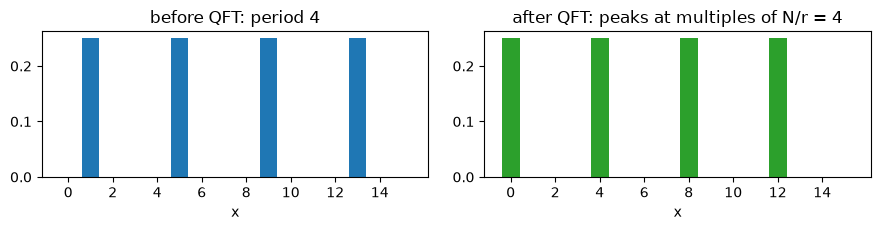

In [10]:
# Period finding in a nutshell: a state with period r=4 inside N=16 amplitudes
n, r = 4, 4
N = 2 ** n
periodic = np.zeros(N, dtype=complex); periodic[1::r] = 1      # amplitude on x = 1, 5, 9, 13
periodic /= np.linalg.norm(periodic)
after = qft_matrix(n) @ periodic

fig, axes = plt.subplots(1, 2, figsize=(9, 2.4))
axes[0].bar(range(N), np.abs(periodic) ** 2); axes[0].set_title("before QFT: period 4")
axes[1].bar(range(N), np.abs(after) ** 2, color="tab:green"); axes[1].set_title("after QFT: peaks at multiples of N/r = 4")
for ax in axes: ax.set_xlabel("x"); ax.set_xticks(range(0, N, 2))
plt.tight_layout(); plt.show()

### 5.2 Phase estimation

**What it is.** Every gate $U$ has special input states (**eigenvectors**) that it only multiplies by a phase: $U\lvert u\rangle = e^{2\pi i\varphi}\lvert u\rangle$. **Quantum phase estimation (QPE)** measures the number $\varphi$ (between 0 and 1) to $m$ binary digits using $m$ extra "counting" qubits.

**How it works.**
1. Put the counting qubits in superposition (H on each).
2. Counting qubit $k$ controls $U^{2^{k}}$ applied to $\lvert u\rangle$. Phase kickback writes $e^{2\pi i \varphi 2^k}$ onto that counting qubit.
3. The counting register is now $\tfrac{1}{\sqrt{2^m}}\sum_x e^{2\pi i\varphi x}\lvert x\rangle$: a wave with frequency $\varphi$.
4. The **inverse QFT** turns that wave into (approximately) the number $x \approx \varphi\, 2^m$. Measure it.

QPE is the core of Shor's algorithm and of quantum chemistry algorithms for exact energies. Here $U$ is a simple phase gate with eigenvector $\lvert 1\rangle$.

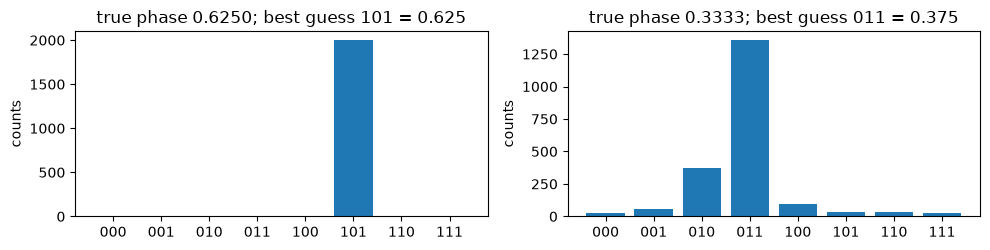

In [11]:
def phase_estimation(phi, m=3, shots=2000):
    """m counting qubits (0..m-1) + 1 target qubit (m) prepared in the eigenstate |1>."""
    sim = QSim(m + 1).x(m)                                  # target in |1>
    h_all(sim, range(m))                                     # counting qubits in superposition
    for q in range(m):
        power = 2 ** (m - 1 - q)                             # qubit 0 is the most significant bit
        sim.gate(CP(2 * np.pi * phi * power), q, m)          # controlled-U^power
    sim.gate(qft_matrix(m).conj().T, *range(m))              # inverse QFT on the counting register
    counts = sim.measure(shots, seed=SEED)
    reg = {}                                                  # keep only the counting bits
    for b, k in counts.items():
        reg[b[:m]] = reg.get(b[:m], 0) + k
    return reg

fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
for ax, phi in zip(axes, [0.625, 1 / 3]):
    reg = phase_estimation(phi)
    best = max(reg, key=reg.get)
    plot_counts(reg, f"true phase {phi:.4f}; best guess {best} = {int(best, 2)/8:.3f}", ax=ax)
plt.show()

**What just happened?** $\varphi = 0.625 = 0.101$ in binary, so 3 counting qubits read it exactly (`101`). $\varphi = 1/3$ has no exact 3-bit form, so the result is spread around the nearest values (`011` = 0.375 and `010` = 0.25). More counting qubits give more digits.

## 6. Shor's algorithm: why it threatens RSA

**What it is.** Shor's algorithm (1994) factors a large number $N$ (writes it as $p\times q$) in **polynomial** time on an error-corrected quantum computer. The best known classical methods take super-polynomial time. It is the most famous **exponential speedup**.

**Why it matters.** The security of **RSA** and of elliptic-curve cryptography (ECC, used in TLS, SSH, digital signatures and cryptocurrencies) rests on factoring and the related discrete-logarithm problem being hard. A large enough quantum computer running Shor's algorithm would break both.

**How it works.** Factoring is turned into **period finding** (also called order finding):
1. Pick a random $a < N$. (If $\gcd(a, N) > 1$ you were lucky and found a factor.)
2. The sequence $a^x \bmod N$ repeats with some period $r$. **Find $r$ with the quantum computer** (QFT-based phase estimation). This is the only quantum step.
3. If $r$ is even, $\gcd(a^{r/2}\pm1, N)$ usually gives the factors. Steps 1 and 3 are fast on a laptop.

Below we do the classical steps for $N = 15$, and we **simulate the quantum step directly as a state** (the full modular-arithmetic circuit is long and not needed to see the idea).

In [12]:
N_factor, a = 15, 7
seq = [pow(a, x, N_factor) for x in range(12)]
print(f"a^x mod {N_factor} for x = 0..11:", seq, " -> repeats every r = 4 (we pretend we do not know r)")

# Quantum step, simulated: a 4-qubit counting register (Q = 16 values of x).
# After computing a^x mod N into a second register and measuring that register (say we saw value 7),
# the counting register keeps only the x with a^x mod N = 7: x = 1, 5, 9, 13 -> a periodic state.
Q = 16
state = np.array([1.0 if pow(a, x, N_factor) == 7 else 0.0 for x in range(Q)], dtype=complex)
state /= np.linalg.norm(state)
probs_y = np.abs(qft_matrix(4) @ state) ** 2               # apply the QFT, then measure
samples = rng.choice(Q, size=8, p=probs_y / probs_y.sum())
print("measured y values:", samples)

# Classical post-processing: y/Q is close to k/r -> continued fractions give r
r_guesses = {Fraction(int(y), Q).limit_denominator(N_factor).denominator for y in samples if y != 0}
r = int(np.lcm.reduce(list(r_guesses)))
print("period r recovered from the samples:", r)
x = pow(a, r // 2, N_factor)
print(f"factors: gcd({x}-1, {N_factor}) = {gcd(x - 1, N_factor)},  gcd({x}+1, {N_factor}) = {gcd(x + 1, N_factor)}")

a^x mod 15 for x = 0..11: [1, 7, 4, 13, 1, 7, 4, 13, 1, 7, 4, 13]  -> repeats every r = 4 (we pretend we do not know r)
measured y values: [ 0 12 12 12  0  4  4 12]
period r recovered from the samples: 4
factors: gcd(4-1, 15) = 3,  gcd(4+1, 15) = 5


**How close is the threat? (keep it in proportion)**

| Fact | Status (as of late 2026, stated generally) |
|---|---|
| Numbers factored with Shor-style circuits on real hardware | only tiny ones such as 15 and 21, often with simplifications that use the known answer |
| Published resource estimates for breaking RSA-2048 | Gidney and Ekerå (2019) estimated about 20 million noisy physical qubits for about 8 hours; Gidney (2025) reported an estimate of under one million noisy qubits running for under a week. Both assume error-corrected hardware that does not exist yet |
| Largest machines today | hundreds to a few thousand physical qubits, with error rates far above what such a run needs |
| Symmetric crypto (AES) and hashes (SHA-2) | Grover gives only a quadratic speedup, so longer keys (AES-256) are considered enough |

**Post-quantum cryptography (PQC)** means classical algorithms that run on normal computers but are believed to resist quantum attacks. NIST published the first standards in 2024: **ML-KEM** (key exchange, FIPS 203), **ML-DSA** (signatures, FIPS 204) and **SLH-DSA** (hash-based signatures, FIPS 205). The danger today is **"harvest now, decrypt later"**: an attacker records encrypted traffic now and decrypts it once a large quantum computer exists. Notebook 04 explains what this means for AI engineers.

## 7. Variational algorithms: a quantum circuit inside a classical optimisation loop

**What it is.** A **variational quantum algorithm** uses a short circuit with adjustable rotation angles $\theta$ (a **parameterised circuit**, or **ansatz**, German for "approach/guess"). The quantum computer evaluates a cost (for example an energy) for the current $\theta$; a **classical optimiser** chooses better angles; repeat.

**Simple analogy.** Tuning an old radio: you (the classical optimiser) turn the knobs, the radio (the quantum circuit) produces a sound, you listen to how clear it is (the cost), and turn the knobs again. Training a neural network works the same way, which is why notebook 03 calls these circuits "quantum neural networks".

```mermaid
flowchart LR
    T[angles theta] --> Q[Quantum circuit<br/>prepare state, measure]
    Q --> E[estimate cost<br/>from shots]
    E --> O[Classical optimiser<br/>COBYLA, Adam, ...]
    O -->|new theta| T
```

**Why they were popular for NISQ machines.** **NISQ** (Noisy Intermediate-Scale Quantum, a term from Preskill 2018) means today's machines: tens to hundreds of good qubits, noisy, no full error correction. Short circuits suffer less noise. **When not:** there is no proof that variational methods beat classical ones, training can get stuck (**barren plateaus**, notebook 03), and every cost value is a noisy shot estimate.

### 7.1 VQE: find the ground-state energy

**What it is.** The **Variational Quantum Eigensolver** (Peruzzo et al., 2014) finds the lowest energy (the **ground state energy**) of a physical system. The system is described by a **Hamiltonian** $H$: a matrix whose smallest eigenvalue is that energy. The **variational principle** guarantees that for any state, $\langle\psi(\theta)\vert H\vert\psi(\theta)\rangle \ge E_{\min}$, so we just minimise the measured energy.

Our toy Hamiltonian is a 2-site **transverse-field Ising model** (two tiny magnets that like to align, plus a sideways field):

$$H = -Z\otimes Z \;-\; 0.5\,(X\otimes I + I\otimes X)$$

For real chemistry (for example the H$_2$ molecule), $H$ is also a sum of such **Pauli strings** (products of I, X, Y, Z); only the coefficients and the number of qubits change.

In [13]:
H_ising = -np.kron(Z, Z) - 0.5 * (np.kron(X, I2) + np.kron(I2, X))
E_exact = np.linalg.eigvalsh(H_ising).min()               # classical answer, for checking
print(f"exact ground energy (classical eigensolver): {E_exact:.4f}")

def ansatz(theta):
    """Hardware-efficient ansatz: RY layer, CNOT, RY layer (4 angles)."""
    return QSim(2).ry(theta[0], 0).ry(theta[1], 1).cx(0, 1).ry(theta[2], 0).ry(theta[3], 1)

def energy(theta):
    psi = ansatz(theta).psi
    return float(np.real(np.vdot(psi, H_ising @ psi)))     # <psi|H|psi>

def energy_from_shots(theta, shots=1000, seed=0):
    """What a real device does: measure each Pauli term from counts.
    ZZ: measure directly. X terms: apply H first (it turns X into Z), then measure."""
    cz = ansatz(theta).measure(shots, seed)
    zz = sum((1 if b[0] == b[1] else -1) * k for b, k in cz.items()) / shots
    cx = ansatz(theta).h(0).h(1).measure(shots, seed + 1)
    x0 = sum((1 if b[0] == "0" else -1) * k for b, k in cx.items()) / shots
    x1 = sum((1 if b[1] == "0" else -1) * k for b, k in cx.items()) / shots
    return -zz - 0.5 * (x0 + x1)

theta0 = rng.uniform(0, 2 * np.pi, 4)
print(f"random start: exact energy {energy(theta0):.3f}, estimated from 1000 shots {energy_from_shots(theta0):.3f}")

exact ground energy (classical eigensolver): -1.4142
random start: exact energy 0.452, estimated from 1000 shots 0.488


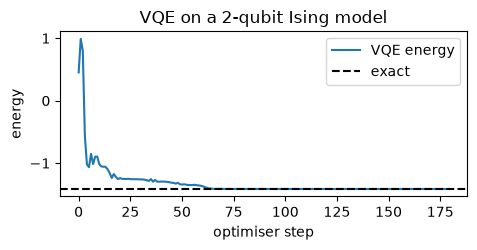

VQE energy -1.4142  vs exact -1.4142  (error 1.2e-09) after 180 evaluations
shot-based check at the optimum: -1.406


In [14]:
history = []
res = minimize(lambda t: (history.append(energy(t)) or history[-1]), theta0, method="COBYLA", options={"maxiter": 200})

plt.figure(figsize=(5, 2.6))
plt.plot(history, label="VQE energy"); plt.axhline(E_exact, c="k", ls="--", label="exact")
plt.xlabel("optimiser step"); plt.ylabel("energy"); plt.title("VQE on a 2-qubit Ising model"); plt.legend()
plt.tight_layout(); plt.show()
print(f"VQE energy {res.fun:.4f}  vs exact {E_exact:.4f}  (error {abs(res.fun - E_exact):.1e}) after {len(history)} evaluations")
print(f"shot-based check at the optimum: {energy_from_shots(res.x, shots=4000):.3f}")

**What just happened?** COBYLA (a derivative-free optimiser) turned the 4 angles until the energy matched the exact answer. With shots, the estimate wobbles around it. On real hardware, noise adds a bias too, and the number of Pauli terms (and so the number of measurements) grows quickly for real molecules. That measurement cost is one of VQE's biggest practical problems.

### 7.2 QAOA: MaxCut on a small graph

**What it is.** **MaxCut**: colour each node of a graph black or white so that as many edges as possible join nodes of *different* colours ("cut" edges). It is a classic hard optimisation problem (NP-hard in general). The **Quantum Approximate Optimization Algorithm** (QAOA, Farhi, Goldstone and Gutmann, 2014) is a variational circuit made for such problems.

**How it works.**
1. Encode a colouring as a bitstring $z$ (one qubit per node). The **cost** $C(z)$ = number of cut edges.
2. Start in $\lvert+\rangle^{\otimes n}$ (all colourings equally likely).
3. Repeat $p$ layers: apply the **cost layer** $e^{-i\gamma C}$ (gives each bitstring a phase proportional to its cost) and the **mixer layer** $e^{-i\beta X}$ on every qubit (an RX rotation that lets amplitude flow between bitstrings).
4. Tune $\gamma, \beta$ with a classical optimiser to maximise the average cut $\langle C\rangle$, then sample bitstrings and keep the best.

brute force: best cut = 4 achieved by ['0101', '1010']


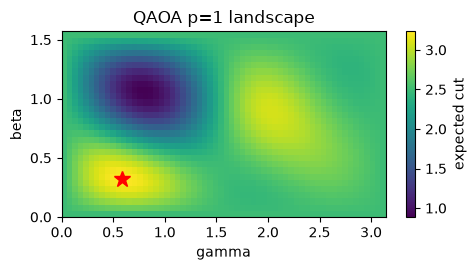

p=1 best on grid: expected cut 3.234  (approximation ratio 0.81)


In [15]:
edges = [(0, 1), (1, 2), (2, 3), (3, 0), (0, 2)]           # a square with one diagonal
n_nodes = 4
def cut_value(b):
    return sum(b[i] != b[j] for i, j in edges)

all_z = bitstrings(n_nodes)
C_diag = np.array([cut_value(b) for b in all_z], dtype=float)
best_cut = C_diag.max()
print("brute force: best cut =", int(best_cut), "achieved by", [b for b in all_z if cut_value(b) == best_cut])

def qaoa_state(gammas, betas):
    sim = h_all(QSim(n_nodes))
    for g, b in zip(gammas, betas):
        sim.psi = np.exp(-1j * g * C_diag) * sim.psi       # cost layer: diagonal phases
        for q in range(n_nodes):
            sim.rx(2 * b, q)                               # mixer layer: e^{-i beta X} = RX(2 beta)
    return sim

def expected_cut(params):
    p = len(params) // 2
    return float(qaoa_state(params[:p], params[p:]).probs() @ C_diag)

# p = 1: scan the whole (gamma, beta) landscape
gs, bs = np.linspace(0, np.pi, 60), np.linspace(0, np.pi / 2, 30)
land = np.array([[expected_cut([g, b]) for g in gs] for b in bs])
i, j = np.unravel_index(land.argmax(), land.shape)
plt.figure(figsize=(5, 2.8))
plt.imshow(land, origin="lower", aspect="auto", extent=[0, np.pi, 0, np.pi / 2], cmap="viridis")
plt.colorbar(label="expected cut"); plt.plot(gs[j], bs[i], "r*", ms=12)
plt.xlabel("gamma"); plt.ylabel("beta"); plt.title("QAOA p=1 landscape"); plt.tight_layout(); plt.show()
print(f"p=1 best on grid: expected cut {land.max():.3f}  (approximation ratio {land.max()/best_cut:.2f})")

p=2 expected cut 3.742  (approximation ratio 0.94)
top samples: [('0101', 427), ('1010', 424), ('1001', 21), ('0110', 20)] 
share of shots that are an optimal cut: 0.85


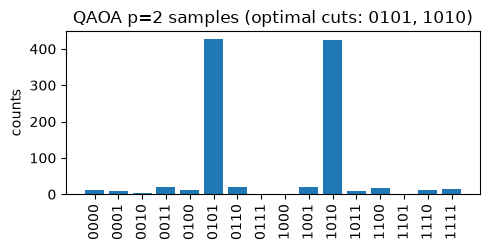

In [16]:
# p = 2: optimise 4 angles from a few random starts
best = None
for start in range(5):
    x0 = rng.uniform(0, np.pi, 4)
    r_ = minimize(lambda t: -expected_cut(t), x0, method="Nelder-Mead", options={"maxiter": 2000})
    if best is None or r_.fun < best.fun:
        best = r_
print(f"p=2 expected cut {-best.fun:.3f}  (approximation ratio {-best.fun/best_cut:.2f})")

sim = qaoa_state(best.x[:2], best.x[2:])
counts = sim.measure(shots=1000, seed=SEED)
p_opt = sum(k for b, k in counts.items() if cut_value(b) == best_cut) / 1000
print("top samples:", counts.most_common(4), f"\nshare of shots that are an optimal cut: {p_opt:.2f}")
plot_counts(counts, "QAOA p=2 samples (optimal cuts: 0101, 1010)"); plt.show()

**What just happened?** With one layer, QAOA already puts extra probability on good cuts. With two layers, most shots are one of the two best cuts (`0101` and `1010`).

**Honest takeaway.** Brute force solved this 4-node graph instantly, and good classical heuristics (for example the Goemans-Williamson algorithm, which guarantees at least 0.878 of the best cut, or simple local search) handle graphs with millions of nodes. As of late 2026 there is **no demonstrated practical advantage** of QAOA over the best classical solvers. It remains an active research area.

## 8. Speedup types: where quantum helps (and where it does not)

| Type of speedup | Examples | Fine print |
|---|---|---|
| **Exponential** (super-polynomial) | Shor (factoring, discrete log); simulating quantum physics and chemistry (phase estimation, Hamiltonian simulation) | needs large, error-corrected machines; chemistry gains depend on the molecule and on how good classical methods already are |
| **Exponential, with strong conditions** | HHL for linear systems | needs fast quantum loading of data (qRAM), a sparse, well-conditioned matrix, and gives a quantum state, not the full answer vector; several "quantum ML" speedups built on it were later **dequantised** (notebook 03) |
| **Quadratic** | Grover search, amplitude amplification, amplitude estimation (Monte Carlo) | real gate speeds and error-correction overhead mean the problem must be very large before it pays off |
| **Polynomial / small** | some graph and optimisation subroutines | often eaten by overheads |
| **None known (heuristic)** | VQE, QAOA, most quantum machine learning, quantum annealing for general optimisation | may work well on some instances, but no proof of advantage; classical heuristics are strong |
| **No speedup possible** | sorting, generic unstructured tasks beyond Grover, adding numbers, serving web pages, most of deep learning training | quantum computers are not general-purpose accelerators |

**Quantum advantage demonstrations.** Since 2019 several groups have reported tasks (mostly sampling from random circuits, and some physics simulations) where a quantum device beat the best known classical simulation. These tasks are chosen to be hard for classical computers, not to be useful, and classical algorithms have later caught up with some of them. As of late 2026, there is no broadly accepted advantage on a commercially useful problem.

## 9. Recap (cheat sheet)

| Algorithm | Problem | Queries / cost | Speedup | Needs error correction? |
|---|---|---|---|---|
| Deutsch-Jozsa | constant vs balanced | 1 query | exponential vs deterministic, none vs randomised | no (toy) |
| Bernstein-Vazirani | hidden string $s$ | 1 query vs n | polynomial | no (toy) |
| Grover | find a marked item | $\approx \frac{\pi}{4}\sqrt N$ | quadratic | yes, for useful sizes |
| QFT | Fourier transform of amplitudes | $\approx n^2/2$ gates | exponential (but output not readable) | building block |
| Phase estimation | eigenvalue phase $\varphi$ | m counting qubits for m bits | building block | yes |
| Shor | factoring, discrete log | polynomial | super-polynomial | yes (millions of physical qubits estimated) |
| VQE | ground-state energy | many shots per step | unknown (heuristic) | designed for NISQ |
| QAOA | combinatorial optimisation | many shots per step | unknown (heuristic) | designed for NISQ |

Key ideas: **oracle**, **phase kickback**, **interference**, **amplitude amplification**, **period finding**, **variational principle**, **hybrid quantum-classical loop**.

## 10. Interview questions

1. **What is an oracle in a quantum algorithm?** A black-box gate that encodes a function; a phase oracle multiplies the amplitude of $\lvert x\rangle$ by $(-1)^{f(x)}$.
2. **What speedup does Grover give, and why is it not "searching a database fast"?** Quadratic ($\sqrt N$ queries vs $N$). Loading a classical database into a quantum state already costs about $N$, and each round is a deep circuit.
3. **What happens if you run too many Grover rounds?** The success probability goes down again; Grover is a rotation that overshoots.
4. **Which step of Shor's algorithm is quantum?** Only period (order) finding, done with phase estimation and the QFT. The rest is classical number theory.
5. **Why does Shor threaten RSA but not AES?** RSA relies on factoring, which Shor solves in polynomial time. Against AES the best known quantum attack is Grover, a quadratic speedup, countered by longer keys.
6. **What is "harvest now, decrypt later"?** Recording encrypted data today to decrypt it once a quantum computer exists; it is why migration to post-quantum cryptography starts now.
7. **What is VQE and what guarantees it is sensible?** A hybrid loop that minimises $\langle\psi(\theta)\vert H\vert\psi(\theta)\rangle$; the variational principle says this is never below the true ground energy.
8. **How is a Hamiltonian measured on hardware?** Write it as a sum of Pauli strings, rotate each term into the Z basis, measure with shots, and add the weighted averages.
9. **What are the two layers of QAOA?** A cost layer $e^{-i\gamma C}$ and a mixer layer $e^{-i\beta\sum X}$, repeated p times with tuned angles.
10. **Does QAOA beat classical MaxCut solvers?** Not demonstrated as of late 2026; classical heuristics and approximation algorithms remain very strong.

## 11. Further reading

- M. A. Nielsen and I. L. Chuang, *Quantum Computation and Quantum Information*, Cambridge University Press, 2010. Chapters 5 (QFT, phase estimation, Shor) and 6 (Grover).
- D. Deutsch and R. Jozsa, "Rapid solution of problems by quantum computation", *Proceedings of the Royal Society A*, 1992.
- L. K. Grover, "A fast quantum mechanical algorithm for database search", STOC 1996.
- P. W. Shor, "Polynomial-Time Algorithms for Prime Factorization and Discrete Logarithms on a Quantum Computer", *SIAM Journal on Computing*, 1997 (conference version 1994).
- A. Peruzzo et al., "A variational eigenvalue solver on a photonic quantum processor", *Nature Communications*, 2014.
- E. Farhi, J. Goldstone and S. Gutmann, "A Quantum Approximate Optimization Algorithm", arXiv:1411.4028 (2014).
- J. Preskill, "Quantum Computing in the NISQ era and beyond", *Quantum* 2, 79 (2018), arXiv:1801.00862.
- C. Gidney and M. Ekerå, "How to factor 2048 bit RSA integers in 8 hours using 20 million noisy qubits", *Quantum*, 2021; and C. Gidney, "How to factor 2048 bit RSA integers with less than a million noisy qubits", 2025.
- NIST FIPS 203 (ML-KEM), FIPS 204 (ML-DSA) and FIPS 205 (SLH-DSA), August 2024.
- Qiskit documentation and IBM Quantum Learning (the successor of the Qiskit textbook): Grover, QFT, phase estimation, VQE and QAOA tutorials.
- PennyLane demos on VQE and QAOA (pennylane.ai/qml).

## Where to go next

- [03_quantum_machine_learning.ipynb](03_quantum_machine_learning.ipynb): variational circuits as classifiers, quantum kernels, barren plateaus.
- [04_quantum_ai_tools_hardware_and_industry.ipynb](04_quantum_ai_tools_hardware_and_industry.ipynb): the same algorithms in Qiskit and PennyLane, hardware, noise and post-quantum cryptography.
- Classical optimisation background: [14_Mathematics/06_optimization.ipynb](../14_Mathematics/06_optimization.ipynb); classical search for comparison: [00_AI_Fundamentals/classical_ai/04_local_search_and_optimization.ipynb](../00_AI_Fundamentals/classical_ai/04_local_search_and_optimization.ipynb).